In [ ]:
import sys
sys.path.append('../../npl_research/')
sys.path.append('src/')
from hcp_IO import load_ts_schaefer300_dict, save_whole_correlations_dict

from utils import sequential_corr_matrices

import matplotlib.pyplot as plt

import pickle as pk

from collections import OrderedDict

from tqdm import tqdm

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Schaefer300

### Load Data

  0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 200/200 [00:08<00:00, 23.41it/s]


The dataset is composed of 100 subjects
Each subject performed 2 trials


Each trial contains 300 time series (number of brain regions)
The lenght of each time serie is 1200 time points




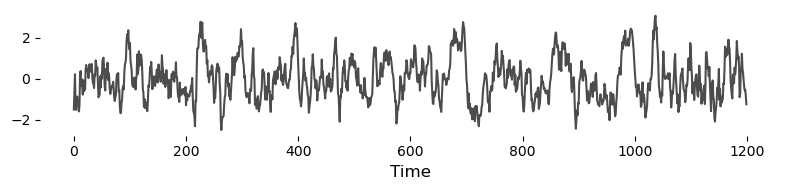

In [3]:
sup_folder = "/data/shared/"
data_dir = sup_folder + 'HCP/100unrelated/schaefer300/no_hp/'
ts = '/ts/LR/'

ts_data = load_ts_schaefer300_dict(data_dir+ts)

print('The dataset is composed of ' + str(len(ts_data.keys())) + ' subjects')
print('Each subject performed ' + str(len(ts_data['103414'].keys())) + ' trials')
print('\n')
print('Each trial contains ' + str(ts_data['103414'][0].shape[1]) +' time series (number of brain regions)')
print('The lenght of each time serie is ' + str(ts_data['103414'][0].shape[0]) + ' time points')
print('\n')


# Plot an example of time serie
fig = plt.figure(figsize=(8,2))
plt.plot(ts_data['103414'][0][:,0], 'k-', alpha=0.7)
plt.box(False)
plt.xlabel('Time', fontsize=12)
plt.tight_layout()

### Compute correlation matrices

In [7]:
save_whole_correlations_dict(ts_data, data_dir)

### Create sliding windows

In [ ]:
# data_dir = sup_folder + 'HCP/100unrelated/schaefer300/null_models/'
# ts = '/ts/mpr/'
# ts_data = load_ts_schaefer300_dict(data_dir+ts)
#Create dictionary of sliding windows TS: sw_dict[width][sub][test][t] = matrix(ROIs x ROIs)
sw_dict = OrderedDict()
widths = [1100,1000,900,800,700,600,500,400,300,200,100,50]
#widths = [200,100]
shifts = [100,100,100,100,100,120,140,160,180,200,220,230]
#shifts = [200,235]


for i, width in tqdm(enumerate(widths), total=len(widths)):
    sw_dict[width] = OrderedDict()
    shift = shifts[i]
    for sub in ts_data:
        sw_dict[width][sub] = OrderedDict()
        for test in ts_data[sub]:
            sw_dict[width][sub][test] = {}
            no_win = int((ts_data[sub][test].shape[0] - width)/shift)+1;
            corrs = sequential_corr_matrices(ts_data[sub][test],width,shift);
            for t in range(no_win):
                sw_dict[width][sub][test][t] = corrs[:,:,t]
                
## dump file
with open('/Data/data/HCP/100unrelated/schaefer300/null_models/fc/mpr/sw_dicts.pck','wb') as f:
    pk.dump(sw_dict, f)